⭐️  🔥  ✔️  ⬇️  ✍️   ✏️   ⚡

## ML5. Decision trees and ensembles - Деревья решений и ансамбли

Задача проекта - по данным соревнования Kaggle **Don't Get Kicked!** предсказать, окажется ли
купленный на аукционе автомобиль «лимоном» (`IsBadBuy = 1`).

Данные те же, что в ML4, но алгоритмы другие: **дерево решений (CART)** и ансамбли над ним -
**Random Forest**, **ExtraTrees** и **градиентный бустинг**. Дерево, лес, ExtraTrees и GBDT
написаны самостоятельно, затем сравниваются с sklearn и с промышленными реализациями бустинга -
LightGBM, XGBoost и CatBoost.

---

### ⬇️ **Задание 1.** 
### *Скачайте данные с соревнования Don’tGetKicked. Спроектируйте разбиение train/validation/test.*

### *Используйте поле `PurchDate` для разбиения: `train.PurchDate < valid.PurchDate < test.PurchDate`. Первая 1/3 данных - обучающая часть, последняя 1/3 - тестовая, средняя 1/3 - валидационная.*

### *Используйте `LabelEncoder` или `OneHotEncoder` из sklearn для предобработки категориальных переменных. Рассмотрите другой подход к кодированию, если встретите новые категориальные значения в валидационной и тестовой выборках.*

Разбиение по времени и границы по квантилям 1/3 и 2/3 - как в ML4. Кодирование другое:
деревьям не нужны ни нормировка, ни one-hot, поэтому категории кодируются **порядковыми номерами**
(`OrdinalEncoder` - это многоколоночный `LabelEncoder`), а высококардинальные признаки -
**частотой в train**.

In [75]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import roc_auc_score
from sklearn.tree import DecisionTreeClassifier as SkDecisionTreeClassifier

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier, Pool

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)

RANDOM_STATE = 21
np.random.seed(RANDOM_STATE)

TARGET = 'IsBadBuy'
DATE_FIELD = 'PurchDate'


def gini(y_true, y_score):
    return abs(2 * roc_auc_score(y_true, y_score) - 1)

Читаем файл и режем по времени на три равные части.

In [76]:
df = pd.read_csv('../datasets/training.csv')
df[DATE_FIELD] = pd.to_datetime(df[DATE_FIELD], format='%m/%d/%Y')

dates = df[DATE_FIELD]
q1, q2 = dates.quantile(1 / 3), dates.quantile(2 / 3)

train = df[dates < q1].copy()
valid = df[(dates >= q1) & (dates < q2)].copy()
test = df[dates >= q2].copy()

split_info = pd.DataFrame([
    {'часть': name, 'строк': len(part),
     'доля': f'{len(part) / len(df):.2%}',
     'дата с': part[DATE_FIELD].min().date(),
     'дата по': part[DATE_FIELD].max().date(),
     'bad-rate': round(part[TARGET].mean(), 4)}
    for name, part in [('train', train), ('valid', valid), ('test', test)]
]).set_index('часть')
display(split_info)

assert train[DATE_FIELD].max() < valid[DATE_FIELD].min()
assert valid[DATE_FIELD].max() < test[DATE_FIELD].min()
assert len(train) + len(valid) + len(test) == len(df)
print('Условие train.PurchDate < valid.PurchDate < test.PurchDate выполнено')

,строк,доля,дата с,дата по,bad-rate
часть,,,,,
train,24232,33.20%,2009-01-05,2009-09-14,0.1148
valid,24414,33.45%,2009-09-15,2010-05-13,0.1300
test,24337,33.35%,2010-05-14,2010-12-30,0.1240


Условие train.PurchDate < valid.PurchDate < test.PurchDate выполнено


In [77]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 72983 entries, 0 to 72982
Data columns (total 34 columns):
 #   Column                             Non-Null Count  Dtype         
---  ------                             --------------  -----         
 0   RefId                              72983 non-null  int64         
 1   IsBadBuy                           72983 non-null  int64         
 2   PurchDate                          72983 non-null  datetime64[us]
 3   Auction                            72983 non-null  str           
 4   VehYear                            72983 non-null  int64         
 5   VehicleAge                         72983 non-null  int64         
 6   Make                               72983 non-null  str           
 7   Model                              72983 non-null  str           
 8   Trim                               70623 non-null  str           
 9   SubModel                           72975 non-null  str           
 10  Color                              72975 non-

Признаки делим на три группы - для каждой свой способ кодирования.

In [78]:
NUMERIC = ['VehYear', 'VehicleAge', 'VehOdo', 'VehBCost', 'WarrantyCost', 'IsOnlineSale',
           'MMRAcquisitionAuctionAveragePrice', 'MMRAcquisitionAuctionCleanPrice',
           'MMRAcquisitionRetailAveragePrice', 'MMRAcquisitonRetailCleanPrice',
           'MMRCurrentAuctionAveragePrice', 'MMRCurrentAuctionCleanPrice',
           'MMRCurrentRetailAveragePrice', 'MMRCurrentRetailCleanPrice']

LOW_CARD = ['Auction', 'Make', 'Color', 'Transmission', 'WheelType', 'Nationality',
            'Size', 'TopThreeAmericanName', 'PRIMEUNIT', 'AUCGUART', 'VNST']

HIGH_CARD = ['Model', 'SubModel', 'Trim', 'BYRNO', 'VNZIP1']

CAT_COLS = LOW_CARD + HIGH_CARD
MMR_COLS = [c for c in NUMERIC if c.startswith('MMR')]

# деревьям пропуск удобно отдать отдельным значением ниже всех настоящих
MISSING = -1

print(f'числовых {len(NUMERIC)}, низкокардинальных {len(LOW_CARD)}, '
      f'высококардинальных {len(HIGH_CARD)}')

числовых 14, низкокардинальных 11, высококардинальных 5


In [79]:
def clean(df_raw):
    out = df_raw.copy()
    out['Transmission'] = out['Transmission'].str.upper()
    for col in ['BYRNO', 'VNZIP1']:
        out[col] = out[col].astype(str)
    out[MMR_COLS] = out[MMR_COLS].replace(0, np.nan)
    return out


class Preprocessor:
    '''Кодировщик под деревья'''

    def fit(self, df_train):
        # OrdinalEncoder; новой категории даём -1
        self.ordinal_ = OrdinalEncoder(handle_unknown='use_encoded_value',
                                       unknown_value=MISSING,
                                       encoded_missing_value=MISSING)
        self.ordinal_.fit(self._cat(df_train))
        self.counts_ = {col: df_train[col].value_counts() for col in HIGH_CARD}
        return self

    def transform(self, df_part):
        num = df_part[NUMERIC].fillna(MISSING)
        num.columns = [f'num__{c}' for c in num.columns]

        cat = pd.DataFrame(self.ordinal_.transform(self._cat(df_part)),
                           columns=[f'ord__{c}' for c in LOW_CARD], index=df_part.index)

        cnt = pd.DataFrame(index=df_part.index)
        for col in HIGH_CARD:
            cnt[f'cnt__{col}'] = df_part[col].map(self.counts_[col]).fillna(0.0)

        return pd.concat([num, cat, cnt], axis=1).astype(float)

    def _cat(self, df_part):
        return df_part[LOW_CARD].astype('object').fillna('__NA__').astype(str)

In [80]:
train_c, valid_c, test_c = clean(train), clean(valid), clean(test)

prep = Preprocessor().fit(train_c)
X_train = prep.transform(train_c)
X_valid = prep.transform(valid_c)
X_test = prep.transform(test_c)

y_train = train[TARGET].to_numpy()
y_valid = valid[TARGET].to_numpy()
y_test = test[TARGET].to_numpy()

# numpy-версии: свои классы работают с массивами
Xtr, Xva, Xte = X_train.to_numpy(), X_valid.to_numpy(), X_test.to_numpy()

print('Размер матрицы признаков:', X_train.shape)
print('Пропусков после кодирования:', int(X_train.isna().sum().sum()))
display(X_train.head(10))

Размер матрицы признаков: (24232, 30)
Пропусков после кодирования: 0


,num__VehYear,num__VehicleAge,num__VehOdo,num__VehBCost,num__WarrantyCost,num__IsOnlineSale,num__MMRAcquisitionAuctionAveragePrice,num__MMRAcquisitionAuctionCleanPrice,num__MMRAcquisitionRetailAveragePrice,num__MMRAcquisitonRetailCleanPrice,num__MMRCurrentAuctionAveragePrice,num__MMRCurrentAuctionCleanPrice,num__MMRCurrentRetailAveragePrice,num__MMRCurrentRetailCleanPrice,ord__Auction,ord__Make,ord__Color,ord__Transmission,ord__WheelType,ord__Nationality,ord__Size,ord__TopThreeAmericanName,ord__PRIMEUNIT,ord__AUCGUART,ord__VNST,cnt__Model,cnt__SubModel,cnt__Trim,cnt__BYRNO,cnt__VNZIP1
426,2005.0,4.0,52492.0,4985.0,754.0,0.0,3885.0,4913.0,4696.0,5806.0,-1.0,-1.0,-1.0,-1.0,0.0,18.0,7.0,0.0,1.0,0.0,5.0,1.0,1.0,1.0,27.0,83.0,84.0,106.0,870.0,68.0
427,2005.0,4.0,62529.0,7825.0,1215.0,0.0,6552.0,7813.0,7576.0,8938.0,6859.0,7868.0,7908.0,8997.0,0.0,4.0,14.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,27.0,262.0,282.0,711.0,870.0,68.0
428,2006.0,3.0,68473.0,6810.0,1703.0,0.0,6707.0,7760.0,7744.0,8881.0,6921.0,7918.0,7975.0,9051.0,0.0,3.0,6.0,0.0,1.0,0.0,2.0,2.0,1.0,1.0,27.0,665.0,1255.0,2979.0,870.0,68.0
429,2005.0,4.0,40556.0,6100.0,623.0,0.0,4792.0,5990.0,5675.0,6969.0,4517.0,5423.0,5378.0,6357.0,0.0,3.0,1.0,0.0,0.0,0.0,0.0,2.0,1.0,1.0,27.0,321.0,4871.0,2979.0,870.0,68.0
430,2003.0,6.0,69946.0,7625.0,1906.0,0.0,4107.0,4728.0,4936.0,5606.0,3768.0,4950.0,4569.0,5846.0,0.0,14.0,2.0,0.0,0.0,2.0,6.0,3.0,1.0,1.0,27.0,26.0,117.0,599.0,870.0,68.0
431,2007.0,2.0,81858.0,6985.0,2282.0,0.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,0.0,3.0,6.0,0.0,0.0,0.0,11.0,2.0,1.0,1.0,27.0,103.0,192.0,2979.0,1021.0,68.0
432,2004.0,5.0,81835.0,5245.0,6519.0,0.0,5650.0,6675.0,6602.0,7709.0,5650.0,6675.0,6602.0,7709.0,0.0,3.0,0.0,0.0,0.0,0.0,11.0,2.0,1.0,1.0,27.0,1.0,16.0,1006.0,1021.0,68.0
433,2003.0,6.0,85629.0,10290.0,1803.0,0.0,8768.0,10655.0,9969.0,12007.0,8768.0,10655.0,9969.0,12007.0,0.0,6.0,14.0,0.0,3.0,0.0,3.0,1.0,1.0,1.0,27.0,78.0,53.0,89.0,1021.0,68.0
434,2004.0,5.0,53292.0,6255.0,1003.0,0.0,5884.0,7207.0,6855.0,8284.0,4607.0,5401.0,7976.0,8623.0,0.0,3.0,5.0,0.0,0.0,0.0,7.0,2.0,1.0,1.0,27.0,4.0,3.0,4511.0,1021.0,68.0
435,2005.0,4.0,80531.0,5475.0,1373.0,0.0,5497.0,7070.0,6437.0,8136.0,5215.0,6837.0,6132.0,7884.0,0.0,3.0,6.0,0.0,0.0,0.0,5.0,2.0,1.0,1.0,27.0,230.0,1255.0,2979.0,1021.0,68.0


Проверим главный риск этих данных - категории, которых не было в обучающей выборке.

In [81]:
rows = []
for col in CAT_COLS:
    seen = set(train_c[col].dropna().unique())
    rows.append({
        'колонка': col,
        'уник. в train': len(seen),
        'строк valid с новой': int((~valid_c[col].isin(seen) & valid_c[col].notna()).sum()),
        'строк test с новой': int((~test_c[col].isin(seen) & test_c[col].notna()).sum()),
    })
unseen = pd.DataFrame(rows).set_index('колонка')
unseen['% test'] = (unseen['строк test с новой'] / len(test) * 100).round(2)
display(unseen.sort_values('строк test с новой', ascending=False).head(8))

,уник. в train,строк valid с новой,строк test с новой,% test
колонка,,,,
Model,801,4360,5597,23.00
BYRNO,35,1330,4380,18.00
PRIMEUNIT,1,11,3346,13.75
VNZIP1,112,841,1811,7.44
VNST,29,51,716,2.94
SubModel,662,241,350,1.44
AUCGUART,1,0,79,0.32
Make,31,10,28,0.12


**Вывод 1**
Данные разбиты по времени на три части по 33 %

Признаков получилось 30. Пропуски кодируются значением `-1`: для дерева это просто ещё одна область, которую оно может
отрезать отдельным разбиением.

---

### ⬇️ **Задание 2.** *Создайте Python-класс для Decision Tree Classifier и Decision Tree Regressor (функция потерь MSE). Он должен поддерживать методы `fit`, `predict_proba` и `predict`. Максимальная глубина (`max_depth`) должна быть параметром класса. В качестве критерия выбора разбиения используйте критерий Джини.*

### *Создайте отдельный класс для Node: он должен хранить данные, вычислять Gini impurity и иметь указатели на потомков (левый и правый). Для регрессора используйте стандартное отклонение вместо Gini impurity. Реализуйте функцию, которая находит наилучшее возможное разбиение в текущем узле. Реализуйте Extra Randomized Tree, спроектировав другую функцию поиска лучшего разбиения.*

In [82]:
class Node:
    '''Узел дерева: хранит данные, считает impurity, ссылается на потомков'''

    def __init__(self, X, y, depth):
        self.X, self.y, self.depth = X, y, depth
        # всё, что нужно для критерия, считаем сразу. данные потом освобождаются
        self.n_samples = len(y)
        self.value = float(y.mean())    # ответ листа: доля единиц или среднее
        self.spread = float(y.std())    # разброс таргета внутри узла
        self.left = None                # указатель на левого потомка
        self.right = None               # указатель на правого потомка
        self.feature = None             # номер признака, по которому делим
        self.threshold = None           # порог разбиения

    def gini(self):
        '''Критерий Джини для бинарного таргета'''
        p = self.value
        return 2 * p * (1 - p)

    def std(self):
        '''Стандартное отклонение таргета - критерий для регрессии'''
        return self.spread

    def is_leaf(self):
        return self.left is None

    def drop_data(self):
        '''После разбиения данные узла больше не нужны - освобождаем память'''
        self.X = self.y = None

In [83]:
class DecisionTree:
    '''Дерево решений criterion: gini (классификация), mse или std (регрессия).'''

    def __init__(self, max_depth=7, criterion='gini', max_features=None,
                 min_samples_leaf=1, splitter='best', random_state=RANDOM_STATE):
        self.max_depth = max_depth
        self.criterion = criterion
        self.max_features = max_features
        self.min_samples_leaf = min_samples_leaf
        self.splitter = splitter
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        self.n_features_ = X.shape[1]
        self.rng_ = np.random.default_rng(self.random_state)
        self.root_ = Node(X, y, depth=0)
        self._grow(self.root_)
        return self

    def _grow(self, node):
        '''Рекурсивно наращивает дерево, пока не сработает критерий останова.'''
        if node.depth >= self.max_depth or node.n_samples < 2 * self.min_samples_leaf:
            return
        if self._impurity(node) <= 1e-12:               # узел уже однородный
            return

        split = self._find_split(node)
        if split is None:
            return

        node.feature, node.threshold = split
        mask = node.X[:, node.feature] <= node.threshold
        node.left = Node(node.X[mask], node.y[mask], node.depth + 1)
        node.right = Node(node.X[~mask], node.y[~mask], node.depth + 1)
        node.drop_data()

        self._grow(node.left)
        self._grow(node.right)

    def _impurity(self, node):
        return node.gini() if self.criterion == 'gini' else node.std()

    def _pick_features(self):
        '''Какие колонки перебирать в узле: все или случайная подвыборка.'''
        if self.max_features is None:
            return range(self.n_features_)
        k = min(self.max_features, self.n_features_)
        return self.rng_.choice(self.n_features_, size=k, replace=False)

    def _find_split(self, node):
        '''Лучшее разбиение узла: best - перебор порогов, random - как у ExtraTrees.'''
        search = self._best_split if self.splitter == 'best' else self._random_split
        best = None
        for feature in self._pick_features():
            found = search(node.X[:, feature], node.y)
            if found is not None and (best is None or found[1] < best[1]):
                best = (feature, found[1], found[0])
        return (best[0], best[2]) if best is not None else None

    def _best_split(self, column, y):
        '''Перебирает все различимые пороги признака. Возвращает (порог, критерий).'''
        order = np.argsort(column, kind='mergesort')
        col, ys = column[order], y[order]
        n = len(ys)

        # границы между разными значениями - это все различимые пороги
        edges = np.flatnonzero(col[1:] != col[:-1])
        msl = self.min_samples_leaf
        edges = edges[(edges + 1 >= msl) & (n - edges - 1 >= msl)]
        if len(edges) == 0:
            return None

        crit = self._criterion_curve(ys, edges)
        best = int(crit.argmin())
        threshold = (col[edges[best]] + col[edges[best] + 1]) / 2
        return threshold, float(crit[best])

    def _random_split(self, column, y):
        '''Extra Randomized Tree: порог берётся случайно, а не перебором.'''
        low, high = column.min(), column.max()
        if low == high:
            return None
        threshold = float(self.rng_.uniform(low, high))

        mask = column <= threshold
        n_left = int(mask.sum())
        if min(n_left, len(y) - n_left) < self.min_samples_leaf:
            return None

        # левую часть укладываем вперёд - тогда работает та же формула критерия
        ordered = np.concatenate([y[mask], y[~mask]])
        crit = self._criterion_curve(ordered, np.array([n_left - 1]))
        return threshold, float(crit[0])

    def _criterion_curve(self, ys, edges):
        '''Взвешенный критерий для каждого порога из edges - через кумулятивные суммы.'''
        n = len(ys)
        n_left = edges + 1
        n_right = n - n_left
        sum_left = np.cumsum(ys)[edges]
        sum_right = ys.sum() - sum_left
        mean_left, mean_right = sum_left / n_left, sum_right / n_right

        if self.criterion == 'gini':
            imp_left = 2 * mean_left * (1 - mean_left)
            imp_right = 2 * mean_right * (1 - mean_right)
        else:
            sq_left = np.cumsum(ys ** 2)[edges]
            sq_right = (ys ** 2).sum() - sq_left
            imp_left = np.maximum(sq_left / n_left - mean_left ** 2, 0)
            imp_right = np.maximum(sq_right / n_right - mean_right ** 2, 0)
            if self.criterion == 'std':          # README просит std, sklearn считает mse
                imp_left, imp_right = np.sqrt(imp_left), np.sqrt(imp_right)

        return (n_left * imp_left + n_right * imp_right) / n

    def _leaf_values(self, X):
        '''Спускает все строки по дереву сразу: на каждом узле делим индексы маской.'''
        out = np.empty(len(X))

        def walk(node, idx):
            if node.is_leaf():
                out[idx] = node.value
                return
            mask = X[idx, node.feature] <= node.threshold
            walk(node.left, idx[mask])
            walk(node.right, idx[~mask])

        walk(self.root_, np.arange(len(X)))
        return out

In [84]:
class DecisionTreeClassifier(DecisionTree):
    '''Дерево классификации: критерий Джини, ответ листа - доля единиц.'''

    def __init__(self, max_depth=7, **kwargs):
        super().__init__(max_depth=max_depth, criterion='gini', **kwargs)

    def predict_proba(self, X):
        p = self._leaf_values(np.asarray(X, dtype=float))
        return np.column_stack([1 - p, p])

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)


class DecisionTreeRegressor(DecisionTree):
    '''Дерево регрессии: критерий MSE (или std), ответ листа - среднее.'''

    def __init__(self, max_depth=7, criterion='mse', **kwargs):
        super().__init__(max_depth=max_depth, criterion=criterion, **kwargs)

    def predict(self, X):
        return self._leaf_values(np.asarray(X, dtype=float))

смотрим на результат обученного дерева.

In [85]:
model = DecisionTreeClassifier(max_depth=7)
model.fit(Xtr, y_train)
proba = model.predict_proba(Xva)

print('predict_proba:', proba.shape, '| сумма по строке =', round(float(proba[0].sum()), 10))
print('predict:      ', np.bincount(model.predict(Xva)), '- сколько нулей и единиц')

root = model.root_
print(f'\nКорень: признак {X_train.columns[root.feature]}, порог {root.threshold:.1f}, '
      f'Gini {root.gini():.4f}')
print(f'Левый потомок:  Gini {root.left.gini():.4f}, объектов {root.left.n_samples}')
print(f'Правый потомок: Gini {root.right.gini():.4f}, объектов {root.right.n_samples}')
print('Указатели на потомков:', type(root.left).__name__, type(root.right).__name__)

predict_proba: (24414, 2) | сумма по строке = 1.0
predict:       [22424  1990] - сколько нулей и единиц

Корень: признак ord__WheelType, порог 2.5, Gini 0.2033
Левый потомок:  Gini 0.1655, объектов 23312
Правый потомок: Gini 0.4045, объектов 920
Указатели на потомков: Node Node


---

### ⬇️ **Задание 3.** *С вашим модулем DecisionTree вы должны получить Gini score не менее 0.1 на валидационном датасете.*

Одно дерево при разной глубине. Заодно видно, где оно начинает переобучаться.

In [86]:
depth_rows = []
for depth in [3, 5, 7, 9, 12, 20]:
    started = time.time()
    tree = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=50).fit(Xtr, y_train)
    depth_rows.append({
        'max_depth': depth,
        'Gini train': round(gini(y_train, tree.predict_proba(Xtr)[:, 1]), 4),
        'Gini valid': round(gini(y_valid, tree.predict_proba(Xva)[:, 1]), 4),
        'время, с': round(time.time() - started, 1)})

depth_df = pd.DataFrame(depth_rows).set_index('max_depth')
display(depth_df)

best_depth = int(depth_df['Gini valid'].idxmax())
print(f'Лучшая глубина по valid: {best_depth}, '
      f'Gini {depth_df.loc[best_depth, "Gini valid"]:.4f} (требуется не меньше 0.1)')

,Gini train,Gini valid,"время, с"
max_depth,,,
3,0.4494,0.4282,0.4
5,0.5033,0.4390,0.2
7,0.5511,0.4222,0.2
9,0.6049,0.4041,0.3
12,0.6841,0.3878,0.5
20,0.7136,0.3789,0.5


Лучшая глубина по valid: 5, Gini 0.4390 (требуется не меньше 0.1)


---

### ⬇️ **Задание 4.** *Используйте `DecisionTreeClassifier` из sklearn и проверьте его качество на валидационном датасете. Лучше ли он, чем ваш модуль? Если да, то почему?*

Сравниваем при одинаковых параметрах - иначе сравнивали бы настройки, а не реализации.

In [87]:
compare_rows = []
for depth in [3, 5, 7, 9, 12]:
    mine = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=50).fit(Xtr, y_train)
    skl = SkDecisionTreeClassifier(max_depth=depth, min_samples_leaf=50, criterion='gini',
                                   random_state=RANDOM_STATE).fit(Xtr, y_train)
    compare_rows.append({
        'max_depth': depth,
        'своё (valid)': round(gini(y_valid, mine.predict_proba(Xva)[:, 1]), 4),
        'sklearn (valid)': round(gini(y_valid, skl.predict_proba(Xva)[:, 1]), 4),
        'своё (train)': round(gini(y_train, mine.predict_proba(Xtr)[:, 1]), 4),
        'sklearn (train)': round(gini(y_train, skl.predict_proba(Xtr)[:, 1]), 4)})

cmp_df = pd.DataFrame(compare_rows).set_index('max_depth')
cmp_df['разница (valid)'] = (cmp_df['sklearn (valid)'] - cmp_df['своё (valid)']).round(4)
display(cmp_df)

,своё (valid),sklearn (valid),своё (train),sklearn (train),разница (valid)
max_depth,,,,,
3,0.4282,0.4413,0.4494,0.4494,0.0131
5,0.4390,0.4441,0.5033,0.5033,0.0051
7,0.4222,0.4232,0.5511,0.5511,0.0010
9,0.4041,0.4106,0.6049,0.6049,0.0065
12,0.3878,0.3882,0.6841,0.6841,0.0004


как нарисовались деревья и почему качество разное на валиде:

In [103]:
from itertools import zip_longest

def own_lines(node, depth=0, side=''):
    '''своё дерево '''
    text = 'лист' if node.is_leaf() else f'{X_train.columns[node.feature]} <= {node.threshold:g}'
    lines = ['    ' * depth + f'{side}{text}  ({node.n_samples}, {node.value:.0%})']
    if not node.is_leaf() and depth < 2:
        lines += own_lines(node.left, depth + 1, 'L ')
        lines += own_lines(node.right, depth + 1, 'R ')
    return lines

def sk_lines(t, i=0, depth=0, side=''):
    '''то же для дерева sklearn'''
    leaf = t.children_left[i] == -1
    text = 'лист' if leaf else f'{X_train.columns[t.feature[i]]} <= {t.threshold[i]:g}'
    share = t.value[i][0][1] / t.value[i][0].sum()
    lines = ['    ' * depth + f'{side}{text}  ({int(t.n_node_samples[i])}, {share:.0%})']
    if not leaf and depth < 2:
        lines += sk_lines(t, t.children_left[i], depth + 1, 'L ')
        lines += sk_lines(t, t.children_right[i], depth + 1, 'R ')
    return lines

mine3 = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50).fit(Xtr, y_train)
skl3 = SkDecisionTreeClassifier(max_depth=3, min_samples_leaf=50,
                                random_state=RANDOM_STATE).fit(Xtr, y_train)

# в скобках сколько машин в узле и какая доля из них лимоны
print(f'{"--- своё дерево ---":<50}--- sklearn ---')
for left, right in zip_longest(own_lines(mine3.root_), sk_lines(skl3.tree_), fillvalue=''):
    print(f'{left:<50}{right}')

print('\nКорреляция VehYear и VehicleAge:')
for name, part in [('train', train), ('valid', valid), ('test', test)]:
    print(f'  {name}: {part["VehYear"].corr(part["VehicleAge"]):.4f}')

--- своё дерево ---                               --- sklearn ---
ord__WheelType <= 2.5  (24232, 11%)               ord__WheelType <= 2.5  (24232, 11%)
    L num__VehYear <= 2003.5  (23312, 9%)             L num__VehicleAge <= 5.5  (23312, 9%)
        L num__VehBCost <= 4197.5  (4742, 17%)            L num__VehicleAge <= 3.5  (18570, 7%)
        R num__VehYear <= 2005.5  (18570, 7%)             R num__VehBCost <= 4197.5  (4742, 17%)
    R ord__Auction <= 0.5  (920, 72%)                 R ord__Auction <= 0.5  (920, 72%)
        L cnt__VNZIP1 <= 449.5  (418, 89%)                L cnt__VNZIP1 <= 449.5  (418, 89%)
        R cnt__VNZIP1 <= 846.5  (502, 57%)                R cnt__VNZIP1 <= 846.5  (502, 57%)

Корреляция VehYear и VehicleAge:
  train: -1.0000
  valid: -0.9584
  test: -1.0000


У sklearn есть параметры, которых у нашего класса нет. Посмотрим, что они дают.

In [89]:
extra_rows = []
for label, kwargs in [
    ('по умолчанию (глубина не ограничена)', {}),
    ('max_depth=5, min_samples_leaf=50', {'max_depth': 5, 'min_samples_leaf': 50}),
    ('+ criterion=entropy', {'max_depth': 5, 'min_samples_leaf': 50, 'criterion': 'entropy'}),
    ('+ class_weight=balanced', {'max_depth': 5, 'min_samples_leaf': 50,
                                 'class_weight': 'balanced'}),
    ('+ ccp_alpha=1e-4 (обрезка)', {'min_samples_leaf': 50, 'ccp_alpha': 1e-4}),
]:
    skl = SkDecisionTreeClassifier(random_state=RANDOM_STATE, **kwargs).fit(Xtr, y_train)
    extra_rows.append({'вариант': label, 'листьев': skl.get_n_leaves(),
                       'Gini train': round(gini(y_train, skl.predict_proba(Xtr)[:, 1]), 4),
                       'Gini valid': round(gini(y_valid, skl.predict_proba(Xva)[:, 1]), 4)})
display(pd.DataFrame(extra_rows).set_index('вариант'))

,листьев,Gini train,Gini valid
вариант,,,
по умолчанию (глубина не ограничена),2603,1.0000,0.2157
"max_depth=5, min_samples_leaf=50",26,0.5033,0.4441
+ criterion=entropy,26,0.5020,0.4273
+ class_weight=balanced,24,0.5026,0.4506
+ ccp_alpha=1e-4 (обрезка),51,0.5138,0.4453


**Ответ на вопрос README: да, sklearn немного лучше:**

колонки train совпадают во всех пяти строках, но в данных есть два признака, которые
на обучающей выборке несут одну и ту же информацию: `VehYear` (год выпуска) и `VehicleAge`
(возраст). Корреляция между ними на train равна -1.0000, потому что почти все покупки
train сделаны в 2009 году и возраст определяется годом выпуска. На train выглядят одинаковыми,
а на валидации - уже нет: valid захватывает и конец 2009, и 2010 год,
там корреляция падает до -0.9584 и каждый год выпуска соответствует уже двум разным
возрастам. Порог «возраст не больше 5 лет» переносится во времени лучше, чем «год выпуска
не раньше 2004».

**sklearn лучше по доп механизмам:**

- Неограниченное дерево: Gini на обучении ровно 1.0000 - переобучена
  (2 603 листа, каждая машина запомнена), а на валидации 0.2157, вдвое хуже
  нашего ограниченного дерева.
- `ccp_alpha` - обрезка дерева после обучения, которой у нас нет: дерево растится
  до конца, а потом слабые ветви удаляются. Даёт 0.4453 при 51 листе, то есть позволяет
  дереву быть сложнее там, где это оправдано, не задавая глубину заранее.
- `class_weight='balanced'` даёт лучший результат таблицы, 0.4506.

---

### ⬇️ **Задание 5.** *Реализуйте RandomForestClassifier и проверьте его качество. Вы должны улучшить результат одиночного дерева и получить Gini score не менее 0.15 на валидационном датасете. Должна быть возможность задать фиксированный random seed.*

In [ ]:
class RandomForestClassifier:
    '''Бэггинг деревьев: каждое учится на своей подвыборке строк и признаков'''

    def __init__(self, number_of_trees=100, max_depth=12, max_features=6, subsample=2 / 3,
                 min_samples_leaf=50, random_state=RANDOM_STATE):
        self.number_of_trees = number_of_trees
        self.max_depth = max_depth
        self.max_features = max_features
        self.subsample = subsample
        self.min_samples_leaf = min_samples_leaf
        self.random_state = random_state

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)
        rng = np.random.default_rng(self.random_state)      # фиксированный seed
        self.trees_ = []
        for _ in range(self.number_of_trees):
            seed = int(rng.integers(10 ** 9))
            rows = self._sample_rows(rng, len(y))
            self.trees_.append(self._make_tree(seed).fit(X[rows], y[rows]))
        return self

    def _sample_rows(self, rng, n):
        '''Бэггинг: 2/3 случайных строк без возвращения'''
        return rng.choice(n, size=int(self.subsample * n), replace=False)

    def _make_tree(self, seed):
        '''Базовая модель леса - обычное дерево с подвыборкой признаков'''
        return DecisionTreeClassifier(max_depth=self.max_depth,
                                      max_features=self.max_features,
                                      min_samples_leaf=self.min_samples_leaf,
                                      random_state=seed)

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        # ответ леса - среднее предсказание всех деревьев
        p = np.mean([tree.predict_proba(X)[:, 1] for tree in self.trees_], axis=0)
        return np.column_stack([1 - p, p])

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

In [91]:
forest_rows = []
for n_trees in [1, 5, 25, 100]:
    started = time.time()
    rf = RandomForestClassifier(number_of_trees=n_trees).fit(Xtr, y_train)
    forest_rows.append({'деревьев': n_trees,
                        'Gini train': round(gini(y_train, rf.predict_proba(Xtr)[:, 1]), 4),
                        'Gini valid': round(gini(y_valid, rf.predict_proba(Xva)[:, 1]), 4),
                        'время, с': round(time.time() - started, 1)})
display(pd.DataFrame(forest_rows).set_index('деревьев'))

rf = RandomForestClassifier(number_of_trees=100).fit(Xtr, y_train)
rf_valid = gini(y_valid, rf.predict_proba(Xva)[:, 1])
print(f'Лес из 100 деревьев: Gini valid {rf_valid:.4f} (требуется не меньше 0.15)')
one_tree = DecisionTreeClassifier(max_depth=12, min_samples_leaf=50).fit(Xtr, y_train)
print(f'Одно дерево той же глубины: {gini(y_valid, one_tree.predict_proba(Xva)[:, 1]):.4f}')

,Gini train,Gini valid,"время, с"
деревьев,,,
1,0.5744,0.3777,0.3
5,0.6665,0.4428,0.4
25,0.6953,0.4704,2.1
100,0.7019,0.4823,7.7


Лес из 100 деревьев: Gini valid 0.4823 (требуется не меньше 0.15)
Одно дерево той же глубины: 0.3878


воспроизводимость: два леса с одним seed

In [92]:
a = RandomForestClassifier(number_of_trees=10, random_state=21).fit(Xtr, y_train)
b = RandomForestClassifier(number_of_trees=10, random_state=21).fit(Xtr, y_train)
c = RandomForestClassifier(number_of_trees=10, random_state=42).fit(Xtr, y_train)

pa, pb, pc = (m.predict_proba(Xva)[:, 1] for m in (a, b, c))
print('seed 21 против seed 21:', 'совпало полностью' if np.allclose(pa, pb) else 'не совпало')
print('seed 21 против seed 42:', f'max расхождение {np.abs(pa - pc).max():.4f},',
      f'Gini {gini(y_valid, pa):.4f} против {gini(y_valid, pc):.4f}')

seed 21 против seed 21: совпало полностью
seed 21 против seed 42: max расхождение 0.3362, Gini 0.4541 против 0.4540


---

### ⬇️ **Задание 6.** *Используйте спроектированный вами класс DecisionTree для GBDT-классификатора. У этого класса должны быть атрибуты `max_depth`, `number_of_trees` и `max_features`. Вы должны вычислить градиент функции потерь binary cross-entropy и реализовать инкрементальное обучение: обучать следующее дерево с использованием результатов предыдущих деревьев.*

**Градиент binary cross-entropy.** Модель хранит не вероятность, а **логит**
$F(x)$, вероятность получается сигмоидой: $p = \sigma(F)$. Функция потерь -

$$L = -\frac{1}{n} \sum_i \left[ y_i \ln p_i + (1 - y_i) \ln (1 - p_i) \right]$$

Производная по логиту сокращается до предельно простого вида (множитель $p(1-p)$ из производной
сигмоиды гасится знаменателем logloss):

$$\frac{\partial L}{\partial F_i} = p_i - y_i, \qquad \text{антиградиент} = y_i - p_i$$

То есть **антиградиент - это просто остаток «правда минус предсказание»**. Каждое следующее
дерево обучается регрессией на этот остаток, и его предсказание добавляется к логиту с шагом
`learning_rate`.

In [93]:
def sigmoid(a):
    '''Численно устойчивая сигмоида: при больших |a| прямая формула переполняет exp().'''
    out = np.empty_like(a, dtype=float)
    pos = a >= 0
    out[pos] = 1 / (1 + np.exp(-a[pos]))
    exp_a = np.exp(a[~pos])
    out[~pos] = exp_a / (1 + exp_a)
    return out


class GradientBoostingClassifier:
    '''GBDT: каждое следующее дерево приближает антиградиент binary cross-entropy.'''

    def __init__(self, number_of_trees=100, max_depth=4, max_features=None,
                 learning_rate=0.1, min_samples_leaf=50, random_state=RANDOM_STATE):
        self.number_of_trees = number_of_trees
        self.max_depth = max_depth
        self.max_features = max_features
        self.learning_rate = learning_rate
        self.min_samples_leaf = min_samples_leaf
        self.random_state = random_state

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)
        rng = np.random.default_rng(self.random_state)

        # стартуем с константы: логит средней доли единиц
        p0 = y.mean()
        self.init_ = float(np.log(p0 / (1 - p0)))
        scores = np.full(len(y), self.init_)

        self.trees_ = []
        for _ in range(self.number_of_trees):
            residual = y - sigmoid(scores)              # антиградиент logloss
            tree = DecisionTreeRegressor(max_depth=self.max_depth,
                                         max_features=self.max_features,
                                         min_samples_leaf=self.min_samples_leaf,
                                         random_state=int(rng.integers(10 ** 9)))
            tree.fit(X, residual)
            # инкрементальное обучение: следующий шаг считается от текущего ансамбля
            scores += self.learning_rate * tree.predict(X)
            self.trees_.append(tree)
        return self

    def decision_function(self, X):
        '''Логит: стартовая константа плюс вклад каждого дерева.'''
        X = np.asarray(X, dtype=float)
        scores = np.full(len(X), self.init_)
        for tree in self.trees_:
            scores += self.learning_rate * tree.predict(X)
        return scores

    def predict_proba(self, X):
        p = sigmoid(self.decision_function(X))
        return np.column_stack([1 - p, p])

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

Обучаем бустинг и смотрим, как качество растёт с каждым добавленным деревом.

Обучение 200 деревьев: 18 с


деревьев,1,5,10,25,50,100,150,200
Gini train,0.4703,0.4827,0.4995,0.5087,0.5156,0.5238,0.5356,0.5468
Gini valid,0.4484,0.4585,0.4626,0.4653,0.4730,0.4725,0.4774,0.4793


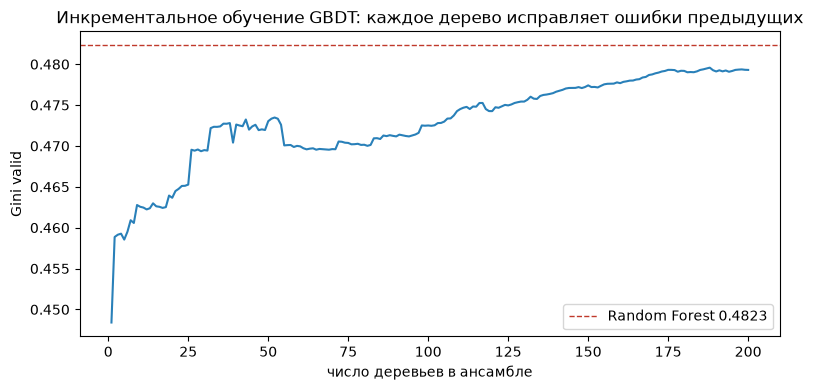

In [95]:
started = time.time()
gb = GradientBoostingClassifier(number_of_trees=200, max_depth=4, learning_rate=0.1,
                                max_features=20).fit(Xtr, y_train)
print(f'Обучение 200 деревьев: {time.time() - started:.0f} с')

# вклад каждого дерева по отдельности - чтобы увидеть кривую обучения
step_tr = np.cumsum([gb.learning_rate * t.predict(Xtr) for t in gb.trees_], axis=0) + gb.init_
step_va = np.cumsum([gb.learning_rate * t.predict(Xva) for t in gb.trees_], axis=0) + gb.init_

checkpoints = [1, 5, 10, 25, 50, 100, 150, 200]
stage_df = pd.DataFrame([
    {'деревьев': k,
     'Gini train': round(gini(y_train, step_tr[k - 1]), 4),
     'Gini valid': round(gini(y_valid, step_va[k - 1]), 4)}
    for k in checkpoints]).set_index('деревьев')
display(stage_df.T)

curve = [gini(y_valid, step_va[k]) for k in range(gb.number_of_trees)]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, gb.number_of_trees + 1), curve, color='#2980b9')
ax.axhline(rf_valid, color='#c0392b', ls='--', lw=1, label=f'Random Forest {rf_valid:.4f}')
ax.set_xlabel('число деревьев в ансамбле')
ax.set_ylabel('Gini valid')
ax.set_title('Инкрементальное обучение GBDT: каждое дерево исправляет ошибки предыдущих')
ax.legend()
plt.tight_layout()
plt.show()

---

### ⬇️ **Задание 7.** *Используйте LightGBM, Catboost и XGBoost для обучения на обучающей выборке и предсказания на валидационной. Изучите документацию библиотек и подберите гиперпараметры алгоритмов под задачу.*

### *Отметьте ключевые различия между реализациями. Проанализируйте особенности каждого алгоритма (как работает «категориальный признак» в Catboost, что такое режим DART в XGBoost?). Какая модель GBDT даёт лучший результат? Можете объяснить почему?*

Сначала все три с одинаковыми параметрами чтобы сравнивать сами реализации

In [96]:
def evaluate(name, p_train, p_valid, seconds, note=''):
    '''Одна строка итоговой таблицы библиотек.'''
    return {'модель': name, 'Gini train': round(gini(y_train, p_train), 4),
            'Gini valid': round(gini(y_valid, p_valid), 4),
            'время, с': round(seconds, 1), 'особенность': note}


base_rows = []

started = time.time()
m = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31, verbose=-1,
                       random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
base_rows.append(evaluate('LightGBM', m.predict_proba(X_train)[:, 1],
                          m.predict_proba(X_valid)[:, 1], time.time() - started,
                          'leafwise-деревья'))

started = time.time()
m = xgb.XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=6, tree_method='hist',
                      random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
base_rows.append(evaluate('XGBoost', m.predict_proba(X_train)[:, 1],
                          m.predict_proba(X_valid)[:, 1], time.time() - started,
                          'depthwise-деревья'))

started = time.time()
m = CatBoostClassifier(iterations=400, learning_rate=0.05, depth=6, verbose=0,
                       random_seed=RANDOM_STATE).fit(X_train, y_train)
base_rows.append(evaluate('CatBoost', m.predict_proba(X_train)[:, 1],
                          m.predict_proba(X_valid)[:, 1], time.time() - started,
                          'oblivious-деревья'))

display(pd.DataFrame(base_rows).set_index('модель'))

,Gini train,Gini valid,"время, с",особенность
модель,,,,
LightGBM,0.9344,0.4460,0.4,leafwise-деревья
XGBoost,0.9157,0.4579,0.5,depthwise-деревья
CatBoost,0.7099,0.4663,1.6,oblivious-деревья


CatBoost получает **сырые строковые категории** через `cat_features`, LightGBM - свои `categorical_feature`, `linear_tree` и `extra_trees`, XGBoost - режим `dart`.

In [ ]:
# CatBoost умеет работать с категориями сам - отдаём ему строки, а не коды
def catboost_frame(part):
    out = part[NUMERIC].fillna(MISSING).copy()
    for col in CAT_COLS:
        out[col] = part[col].astype('object').fillna('__NA__').astype(str)
    return out


CB_train, CB_valid, CB_test = (catboost_frame(p) for p in (train_c, valid_c, test_c))

LGB_CAT = [f'ord__{c}' for c in LOW_CARD]


def lgb_frame(part, categories=None):
    out = part.copy()
    for col in LGB_CAT:
        codes = out[col].astype(int)
        out[col] = pd.Categorical(codes, categories=categories[col] if categories else None)
    return out


L_train = lgb_frame(X_train)
CATEGORIES = {col: L_train[col].cat.categories for col in LGB_CAT}
L_valid, L_test = (lgb_frame(p, CATEGORIES) for p in (X_valid, X_test))

print('CatBoost получает', len(CAT_COLS), 'категориальных колонок строками')
print('LightGBM получает', len(LGB_CAT), 'колонок типа category')

CatBoost получает 16 категориальных колонок строками
LightGBM получает 11 колонок типа category


In [98]:
special_rows = []

for label, kwargs, frames in [
    ('LightGBM + categorical_feature', {}, (L_train, L_valid)),
    ('LightGBM + linear_tree', {'linear_tree': True}, (X_train, X_valid)),
    ('LightGBM + extra_trees', {'extra_trees': True}, (X_train, X_valid)),
    ('LightGBM + dart', {'boosting_type': 'dart'}, (X_train, X_valid)),
]:
    Xt, Xv = frames
    started = time.time()
    m = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31, verbose=-1,
                           random_state=RANDOM_STATE, n_jobs=-1, **kwargs).fit(Xt, y_train)
    special_rows.append(evaluate(label, m.predict_proba(Xt)[:, 1], m.predict_proba(Xv)[:, 1],
                                 time.time() - started, str(kwargs or 'category-колонки')))

started = time.time()
m = xgb.XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=6, booster='dart',
                      rate_drop=0.1, skip_drop=0.5, tree_method='hist',
                      random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
special_rows.append(evaluate('XGBoost + dart', m.predict_proba(X_train)[:, 1],
                             m.predict_proba(X_valid)[:, 1], time.time() - started,
                             'выбрасывает часть деревьев'))

started = time.time()
m = CatBoostClassifier(iterations=400, learning_rate=0.05, depth=6, verbose=0,
                       random_seed=RANDOM_STATE)
m.fit(Pool(CB_train, y_train, cat_features=CAT_COLS))
special_rows.append(evaluate('CatBoost + cat_features', m.predict_proba(CB_train)[:, 1],
                             m.predict_proba(CB_valid)[:, 1], time.time() - started,
                             'ordered target encoding'))

display(pd.DataFrame(special_rows).set_index('модель'))

,Gini train,Gini valid,"время, с",особенность
модель,,,,
LightGBM + categorical_feature,0.9516,0.4593,0.7,category-колонки
LightGBM + linear_tree,0.9825,0.3175,0.6,{'linear_tree': True}
LightGBM + extra_trees,0.8232,0.4478,0.5,{'extra_trees': True}
LightGBM + dart,0.7715,0.4778,1.2,{'boosting_type': 'dart'}
XGBoost + dart,0.8162,0.4616,4.7,выбрасывает часть деревьев
CatBoost + cat_features,0.6299,0.4921,18.6,ordered target encoding


Подбор гиперпараметров. Число деревьев не угадываем, а находим **ранней остановкой**
по валидационной выборке: обучение прекращается, когда AUC на valid перестаёт расти 100 итераций.

In [99]:
tuned = {}
tuned_rows = []

for leaves in [15, 31, 63]:
    started = time.time()
    m = lgb.LGBMClassifier(n_estimators=2000, learning_rate=0.03, num_leaves=leaves,
                           min_child_samples=50, colsample_bytree=0.8, subsample=0.8,
                           subsample_freq=1, reg_lambda=1.0, verbose=-1,
                           random_state=RANDOM_STATE, n_jobs=-1)
    m.fit(L_train, y_train, eval_set=[(L_valid, y_valid)], eval_metric='auc',
          callbacks=[lgb.early_stopping(100, verbose=False)])
    row = evaluate(f'LightGBM num_leaves={leaves}', m.predict_proba(L_train)[:, 1],
                   m.predict_proba(L_valid)[:, 1], time.time() - started,
                   f'{m.best_iteration_} деревьев')
    tuned_rows.append(row)
    tuned[row['модель']] = m

for depth in [4, 6]:
    started = time.time()
    m = xgb.XGBClassifier(n_estimators=2000, learning_rate=0.03, max_depth=depth,
                          min_child_weight=20, colsample_bytree=0.8, subsample=0.8,
                          reg_lambda=1.0, tree_method='hist', eval_metric='auc',
                          early_stopping_rounds=100, random_state=RANDOM_STATE, n_jobs=-1)
    m.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=False)
    row = evaluate(f'XGBoost max_depth={depth}', m.predict_proba(X_train)[:, 1],
                   m.predict_proba(X_valid)[:, 1], time.time() - started,
                   f'{m.best_iteration} деревьев')
    tuned_rows.append(row)
    tuned[row['модель']] = m

for depth in [4, 6]:
    started = time.time()
    m = CatBoostClassifier(iterations=2000, learning_rate=0.03, depth=depth, l2_leaf_reg=3.0,
                           eval_metric='AUC', early_stopping_rounds=100, verbose=0,
                           random_seed=RANDOM_STATE)
    m.fit(Pool(CB_train, y_train, cat_features=CAT_COLS),
          eval_set=Pool(CB_valid, y_valid, cat_features=CAT_COLS))
    row = evaluate(f'CatBoost depth={depth} + cat_features', m.predict_proba(CB_train)[:, 1],
                   m.predict_proba(CB_valid)[:, 1], time.time() - started,
                   f'{m.best_iteration_} деревьев')
    tuned_rows.append(row)
    tuned[row['модель']] = m

tuned_df = pd.DataFrame(tuned_rows).set_index('модель').sort_values('Gini valid',
                                                                   ascending=False)
display(tuned_df)

best_name = tuned_df.index[0]
best_model = tuned[best_name]
print(f'Лучшая библиотечная модель: {best_name}, Gini valid {tuned_df.iloc[0]["Gini valid"]}')

,Gini train,Gini valid,"время, с",особенность
модель,,,,
CatBoost depth=4 + cat_features,0.6269,0.4993,46.8,1290 деревьев
CatBoost depth=6 + cat_features,0.6128,0.4978,31.9,498 деревьев
LightGBM num_leaves=15,0.5926,0.4876,0.3,92 деревьев
XGBoost max_depth=6,0.5907,0.4871,0.6,63 деревьев
LightGBM num_leaves=31,0.6464,0.4863,0.3,73 деревьев
LightGBM num_leaves=63,0.6961,0.4810,0.5,48 деревьев
XGBoost max_depth=4,0.5343,0.4803,0.5,58 деревьев


Лучшая библиотечная модель: CatBoost depth=4 + cat_features, Gini valid 0.4993


---

### ⬇️ **Задание 8.** *Возьмите лучшую модель и оцените её качество на тестовом датасете: проверьте значения Gini на всех трёх датасетах для вашей лучшей модели: training Gini, valid Gini, test Gini. Видите ли вы падение качества при сравнении валидационного качества с тестовым? Переобучена ваша модель или нет? Объясните.*

In [100]:
def three_parts(name, predict):
    '''Gini на train / valid / test для одной модели.'''
    row = {'модель': name}
    for part, y_part in [('train', y_train), ('valid', y_valid), ('test', y_test)]:
        row[f'Gini {part}'] = round(gini(y_part, predict(part)), 4)
    row['train - valid'] = round(row['Gini train'] - row['Gini valid'], 4)
    row['valid - test'] = round(row['Gini valid'] - row['Gini test'], 4)
    return row


single_tree = DecisionTreeClassifier(max_depth=5, min_samples_leaf=50).fit(Xtr, y_train)
own_frames = {'train': Xtr, 'valid': Xva, 'test': Xte}
cb_frames = {'train': CB_train, 'valid': CB_valid, 'test': CB_test}
lgb_frames = {'train': L_train, 'valid': L_valid, 'test': L_test}
plain_frames = {'train': X_train, 'valid': X_valid, 'test': X_test}

final_rows = [
    three_parts('CatBoost depth=4 + cat_features (лучшая)',
                lambda p: best_model.predict_proba(cb_frames[p])[:, 1]),
    three_parts('LightGBM num_leaves=15',
                lambda p: tuned['LightGBM num_leaves=15'].predict_proba(lgb_frames[p])[:, 1]),
    three_parts('XGBoost max_depth=6',
                lambda p: tuned['XGBoost max_depth=6'].predict_proba(plain_frames[p])[:, 1]),
    three_parts('свой GBDT (200 деревьев)',
                lambda p: gb.predict_proba(own_frames[p])[:, 1]),
    three_parts('свой RandomForest (100 деревьев)',
                lambda p: rf.predict_proba(own_frames[p])[:, 1]),
    three_parts('своё одно дерево (max_depth=5)',
                lambda p: single_tree.predict_proba(own_frames[p])[:, 1]),
]
final_df = pd.DataFrame(final_rows).set_index('модель')
display(final_df)

,Gini train,Gini valid,Gini test,train - valid,valid - test
модель,,,,,
CatBoost depth=4 + cat_features (лучшая),0.6269,0.4993,0.4606,0.1276,0.0387
LightGBM num_leaves=15,0.5926,0.4876,0.5013,0.1050,-0.0137
XGBoost max_depth=6,0.5907,0.4871,0.4982,0.1036,-0.0111
свой GBDT (200 деревьев),0.5468,0.4793,0.4914,0.0675,-0.0121
свой RandomForest (100 деревьев),0.7019,0.4823,0.4893,0.2196,-0.0070
своё одно дерево (max_depth=5),0.5033,0.4390,0.4624,0.0643,-0.0234


---

### ⭐️ **Задание 9.** *Реализуйте ExtraTreesClassifier и проверьте его качество. Вы должны улучшить результат одиночного дерева и получить Gini score не менее 0.12 на валидационном датасете.*

ExtraTrees отличается от леса двумя вещами: подвыборки строк нет, а порог в узле берётся
**случайно** вместо перебора. И то и другое у нас уже есть, поэтому класс наследуется
от `RandomForestClassifier` и переопределяет два метода.

In [ ]:
class ExtraTreesClassifier(RandomForestClassifier):

    def _sample_rows(self, rng, n):
        '''каждое дерево видит всю выборку'''
        return np.arange(n)

    def _make_tree(self, seed):
        '''Базовая модель - extra randomized tree: splitter='random'.'''
        return DecisionTreeClassifier(max_depth=self.max_depth,
                                      max_features=self.max_features,
                                      min_samples_leaf=self.min_samples_leaf,
                                      splitter='random', random_state=seed)

In [102]:
et_rows = []
for n_trees, max_features in [(25, 10), (100, 6), (100, 10), (100, 20)]:
    started = time.time()
    et = ExtraTreesClassifier(number_of_trees=n_trees, max_depth=12,
                              max_features=max_features).fit(Xtr, y_train)
    et_rows.append({'деревьев': n_trees, 'max_features': max_features,
                    'Gini train': round(gini(y_train, et.predict_proba(Xtr)[:, 1]), 4),
                    'Gini valid': round(gini(y_valid, et.predict_proba(Xva)[:, 1]), 4),
                    'время, с': round(time.time() - started, 1)})
et_df = pd.DataFrame(et_rows).set_index(['деревьев', 'max_features'])
display(et_df)

et = ExtraTreesClassifier(number_of_trees=100, max_depth=12, max_features=10).fit(Xtr, y_train)
et_valid = gini(y_valid, et.predict_proba(Xva)[:, 1])

one_random = DecisionTreeClassifier(max_depth=12, min_samples_leaf=50, splitter='random',
                                    max_features=10).fit(Xtr, y_train)
print(f'ExtraTrees из 100 деревьев: Gini valid {et_valid:.4f} (требуется не меньше 0.12)')
print(f'Одно extra randomized tree:  '
      f'{gini(y_valid, one_random.predict_proba(Xva)[:, 1]):.4f}')
print(f'Для сравнения RandomForest:  {rf_valid:.4f}')
print(f'Gini test:                   {gini(y_test, et.predict_proba(Xte)[:, 1]):.4f}')

Gini train  Gini valid  время, с
деревьев max_features                                  
25       10                0.6304      0.4808       2.2
100      6                 0.6021      0.4749       5.5
         10                0.6365      0.4825       7.5
         20                0.6702      0.4836      12.5

ExtraTrees из 100 деревьев: Gini valid 0.4825 (требуется не меньше 0.12)
Одно extra randomized tree:  0.4086
Для сравнения RandomForest:  0.4823
Gini test:                   0.4936
